### static sparse sweep

In [ ]:
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from torch.cuda.amp import autocast, GradScaler

# ==========================================
# 0. Config & Reproducibility
# ==========================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = False # Better reproducibility across seeds
        torch.backends.cudnn.deterministic = True

def get_device():
    return 'cuda' if torch.cuda.is_available() else 'cpu'

# ==========================================
# 1. Architecture: ResNet-9
# ==========================================
def conv_bn(c_in, c_out, k=3, s=1, p=1, pool=False):
    layers = [
        nn.Conv2d(c_in, c_out, kernel_size=k, stride=s, padding=p, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True)
    ]
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class ResNet9(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.prep = conv_bn(3, 64)
        self.layer1 = conv_bn(64, 128, pool=True)
        self.res1 = nn.Sequential(conv_bn(128, 128), conv_bn(128, 128))
        self.layer2 = conv_bn(128, 256, pool=True)
        self.layer3 = conv_bn(256, 512, pool=True)
        self.res3 = nn.Sequential(conv_bn(512, 512), conv_bn(512, 512))
        self.pool = nn.MaxPool2d(4)
        self.linear = nn.Linear(512, num_classes)

    def forward(self, x):
        out = self.prep(x)
        out = self.layer1(out)
        out = out + self.res1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = out + self.res3(out)
        out = self.pool(out)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

# ==========================================
# 2. Helpers
# ==========================================
def print_active_parameters(model, masks=None):
    total_params = 0
    active_params = 0
    if masks is not None and len(masks) > 0:
        for name, param in model.named_parameters():
            numel = param.numel()
            total_params += numel
            if name in masks:
                active_params += masks[name].sum().item()
            else:
                active_params += numel
    else:
        for param in model.parameters():
            total_params += param.numel()
            active_params += (param != 0).sum().item()

    sparsity = 1.0 - (active_params / total_params) if total_params > 0 else 0.0
    print(f"Total Params: {total_params:,} | Active: {active_params:,} | Actual Sparsity: {sparsity:.2%}")
    return active_params, total_params

def create_static_masks(model, target_sparsity):
    masks = {}
    if target_sparsity > 0.0:
        # Don't prune the first layer, classifier, or BatchNorms
        dense_layers = ['prep', 'linear', 'bn']
        for n, p in model.named_parameters():
            if p.ndim < 2 or any(k in n for k in dense_layers):
                continue
            # Random uniform mask
            masks[n] = (torch.rand_like(p) > target_sparsity).bool()

            # Apply mask strictly to weights
            with torch.no_grad():
                p.data *= masks[n]
    return masks

# ==========================================
# 3. Training Logic (Static)
# ==========================================
def train_static_model(model, masks, trainloader, valloader, lr, epochs, device):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)
    scaler = GradScaler()

    history = {'loss_train': [], 'loss_val': [], 'acc': []}

    for ep in range(epochs):
        model.train()
        train_loss = 0

        for bx, by in trainloader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()

            with autocast():
                out = model(bx)
                loss = F.cross_entropy(out, by, label_smoothing=0.1)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            # --- STATIC SPARSITY GRADIENT MASKING ---
            # Zero out gradients for pruned weights so they don't update
            if masks:
                with torch.no_grad():
                    for n, p in model.named_parameters():
                        if n in masks and p.grad is not None:
                            p.grad *= masks[n]

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()

        train_loss /= len(trainloader)

        # Validation
        model.eval()
        val_loss = 0; correct = 0; total = 0
        with torch.no_grad():
            for bx, by in valloader:
                bx, by = bx.to(device), by.to(device)
                with autocast():
                    out = model(bx)
                    l = F.cross_entropy(out, by)
                val_loss += l.item()
                correct += (out.argmax(1) == by).sum().item()
                total += by.size(0)

        val_loss /= len(valloader)
        acc = correct / total

        scheduler.step()

        history['loss_train'].append(train_loss)
        history['loss_val'].append(val_loss)
        history['acc'].append(acc)

    return history

# ==========================================
# 4. Sweep Runner
# ==========================================
def run_sweep(
    sparsities=[0.5, 0.8, 0.9],
    learning_rates=[0.1, 0.05, 0.01],
    seeds=[42, 43, 44],
    epochs=50,
    batch_size=128,
    use_cifar100=False
):
    device = get_device()
    dataset_name = "CIFAR-100" if use_cifar100 else "CIFAR-10"
    print(f"=== Starting Sweep on {dataset_name} ===")
    print(f"Sparsities: {sparsities}")
    print(f"LRs: {learning_rates}")
    print(f"Seeds: {seeds}")

    # --- Load Data Once ---
    stats = ((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    t_train = transforms.Compose([
        transforms.RandomCrop(32, 4), transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize(*stats)
    ])
    t_val = transforms.Compose([transforms.ToTensor(), transforms.Normalize(*stats)])

    torchvision.datasets.CIFAR10.url = "https://huggingface.co/datasets/liangnanying/cifar-10-python/resolve/main/cifar-10-python.tar.gz"

    if use_cifar100:
        trainset = torchvision.datasets.CIFAR100('./data', train=True, download=True, transform=t_train)
        valset = torchvision.datasets.CIFAR100('./data', train=False, download=True, transform=t_val)
        num_classes = 100
    else:
        trainset = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=t_train)
        valset = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=t_val)
        num_classes = 10

    trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    valloader = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)

    all_results = []

    # --- Sweep Loop ---
    for sp in sparsities:
        for lr in learning_rates:
            for seed in seeds:
                print(f"\n--- Running Config | Sparsity: {sp} | LR: {lr} | Seed: {seed} ---")

                # 1. Reproducibility
                set_seed(seed)

                # 2. Init Model & Masks
                model = ResNet9(num_classes).to(device)
                masks = create_static_masks(model, sp)

                if seed == seeds[0]: # Just print stats on the first seed
                    print_active_parameters(model, masks)

                # 3. Train
                start_time = time.time()
                hist = train_static_model(model, masks, trainloader, valloader, lr, epochs, device)
                end_time = time.time()

                best_acc = max(hist['acc'])

                print(f"--> Finished in {(end_time-start_time)/60:.1f}m | Best Val Acc: {best_acc:.2%}")

                all_results.append({
                    'sparsity': sp,
                    'lr': lr,
                    'seed': seed,
                    'best_acc': best_acc,
                    'history': hist
                })

    plot_sweep_results(all_results, sparsities, learning_rates, epochs)
    return all_results

# ==========================================
# 5. Plotting Results
# ==========================================
def plot_sweep_results(results, sparsities, learning_rates, epochs):
    """
    Plots the mean +/- std of the validation accuracy across seeds
    for each Sparsity and LR combination.
    """
    fig, axes = plt.subplots(1, len(sparsities), figsize=(5 * len(sparsities), 5), sharey=True)
    if len(sparsities) == 1: axes = [axes]

    for i, sp in enumerate(sparsities):
        ax = axes[i]
        ax.set_title(f"Target Sparsity: {sp*100:.0f}%")
        ax.set_xlabel("Epochs")
        if i == 0: ax.set_ylabel("Validation Accuracy")

        for lr in learning_rates:
            # Gather histories for all seeds corresponding to this Sp/LR combo
            group_accs = [r['history']['acc'] for r in results if r['sparsity'] == sp and r['lr'] == lr]

            if not group_accs: continue

            accs_np = np.array(group_accs) # Shape: (num_seeds, epochs)
            mean_acc = accs_np.mean(axis=0)
            std_acc = accs_np.std(axis=0)

            x = range(epochs)
            line, = ax.plot(x, mean_acc, label=f"LR: {lr}")
            ax.fill_between(x, mean_acc - std_acc, mean_acc + std_acc, alpha=0.2, color=line.get_color())

        ax.grid(True, alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()


In [ ]:

sweep_results = run_sweep(
    sparsities=[0.99, 0.95, .9, .8],
    learning_rates=[0.1, 0.05, 0.01],
    seeds=[42, 43, 44],
    epochs=35,
    batch_size=512,
    use_cifar100=False
)

=== Starting Sweep on CIFAR-10 ===
Sparsities: [0.99, 0.95, 0.9, 0.8]
LRs: [0.1, 0.05, 0.01]
Seeds: [42, 43, 44]

--- Running Config | Sparsity: 0.99 | LR: 0.1 | Seed: 42 ---
Total Params: 6,573,130 | Active: 76,635 | Actual Sparsity: 98.83%


/tmp/ipykernel_4614/303072787.py:110: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_4614/303072787.py:122: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_4614/303072787.py:150: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


--> Finished in 12.1m | Best Val Acc: 82.15%

--- Running Config | Sparsity: 0.99 | LR: 0.1 | Seed: 43 ---
--> Finished in 12.4m | Best Val Acc: 83.01%

--- Running Config | Sparsity: 0.99 | LR: 0.1 | Seed: 44 ---
--> Finished in 12.0m | Best Val Acc: 82.05%

--- Running Config | Sparsity: 0.99 | LR: 0.05 | Seed: 42 ---
Total Params: 6,573,130 | Active: 76,635 | Actual Sparsity: 98.83%
--> Finished in 12.0m | Best Val Acc: 81.84%

--- Running Config | Sparsity: 0.99 | LR: 0.05 | Seed: 43 ---
--> Finished in 11.8m | Best Val Acc: 81.75%

--- Running Config | Sparsity: 0.99 | LR: 0.05 | Seed: 44 ---
--> Finished in 11.6m | Best Val Acc: 81.69%

--- Running Config | Sparsity: 0.99 | LR: 0.01 | Seed: 42 ---
Total Params: 6,573,130 | Active: 76,635 | Actual Sparsity: 98.83%
--> Finished in 11.7m | Best Val Acc: 77.93%

--- Running Config | Sparsity: 0.99 | LR: 0.01 | Seed: 43 ---
--> Finished in 11.9m | Best Val Acc: 78.74%

--- Running Config | Sparsity: 0.99 | LR: 0.01 | Seed: 44 ---
--> 

### small ResNets: size sweep

In [ ]:
import os
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as transforms


from torch.amp import autocast, GradScaler

# ==========================================
# 0. Config & Reproducibility
# ==========================================
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True

def get_device(): return 'cuda' if torch.cuda.is_available() else 'cpu'

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

# ==========================================
# 1. Architecture: Scalable ResNet-9
# ==========================================
def conv_bn(c_in, c_out, k=3, s=1, p=1, pool=False):
    layers = [
        nn.Conv2d(c_in, c_out, kernel_size=k, stride=s, padding=p, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True)
    ]
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class SmallResNet9(nn.Module):
    def __init__(self, base_c=16, num_classes=10):
        super().__init__()
        self.prep = conv_bn(3, base_c)
        self.layer1 = conv_bn(base_c, base_c*2, pool=True)
        self.res1 = nn.Sequential(conv_bn(base_c*2, base_c*2), conv_bn(base_c*2, base_c*2))
        self.layer2 = conv_bn(base_c*2, base_c*4, pool=True)
        self.layer3 = conv_bn(base_c*4, base_c*8, pool=True)
        self.res3 = nn.Sequential(conv_bn(base_c*8, base_c*8), conv_bn(base_c*8, base_c*8))
        self.pool = nn.MaxPool2d(4)
        self.linear = nn.Linear(base_c*8, num_classes)

    def forward(self, x):
        out = self.prep(x)
        out = self.layer1(out)
        out = out + self.res1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = out + self.res3(out)
        out = self.pool(out)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

# ==========================================
# 2. Training Logic
# ==========================================
def get_dataloaders(batch_size=512):
    stats = ((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    t_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(*stats)
    ])
    t_val = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize(*stats)
    ])

    torchvision.datasets.CIFAR10.url = "https://huggingface.co/datasets/liangnanying/cifar-10-python/resolve/main/cifar-10-python.tar.gz"

    trainset = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=t_train)
    valset = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=t_val)


    trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    valloader = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    return trainloader, valloader

def train_model(model, trainloader, valloader, device, epochs=20, lr=0.1):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)


    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    scaler = GradScaler('cuda')

    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    start_time = time.time()
    for ep in range(epochs):
        # --- TRAIN ---
        model.train()
        train_loss = 0
        for bx, by in trainloader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()

            with autocast('cuda'):
                out = model(bx)
                loss = F.cross_entropy(out, by, label_smoothing=0.1)

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()

        # CosineAnnealing steps per epoch
        scheduler.step()

        # --- EVALUATE ---
        model.eval()
        val_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for bx, by in valloader:
                bx, by = bx.to(device), by.to(device)
                with autocast('cuda'):
                    out = model(bx)
                    l = F.cross_entropy(out, by)
                val_loss += l.item()
                correct += (out.argmax(1) == by).sum().item()
                total += by.size(0)

        acc = correct / total

        # Log history
        history['train_loss'].append(train_loss / len(trainloader))
        history['val_loss'].append(val_loss / len(valloader))
        history['val_acc'].append(acc)

        if (ep + 1) % 5 == 0 or ep == epochs - 1:
            print(f"   Epoch [{ep+1:02d}/{epochs}] | Train Loss: {history['train_loss'][-1]:.3f} | Val Acc: {acc:.2%}")

    run_time = time.time() - start_time
    print(f"   -> Finished in {run_time/60:.2f} mins. Best Acc: {max(history['val_acc']):.2%}\n")
    return history

# ==========================================
# 3. Experiment Runner & Plotting
# ==========================================

def run_size_experiments(epochs_per_model=30, channel_configs=[6, 8, 12, 16], learning_rates=[0.1, 0.05], seeds=[42, 43, 44]):
    device = get_device()
    print(f"Using device: {device}\n")

    # High batch size for faster throughput
    trainloader, valloader = get_dataloaders(batch_size=512)

    all_results = {}
    total_start = time.time()

    for base_c in channel_configs:
        all_results[base_c] = {}
        for lr in learning_rates:
            all_results[base_c][lr] = []

            for seed in seeds:
                set_seed(seed)

                model = SmallResNet9(base_c=base_c, num_classes=10).to(device)
                params = count_parameters(model)

                print("="*65)
                print(f"Config: base_c={base_c} | LR={lr} | Seed={seed} | Params: {params:,}")
                print("="*65)

                hist = train_model(model, trainloader, valloader, device, epochs=epochs_per_model, lr=lr)

                all_results[base_c][lr].append({
                    'params': params,
                    'history': hist,
                    'best_acc': max(hist['val_acc'])
                })

    print(f"ALL MODELS FINISHED! Total Time: {(time.time() - total_start)/60:.2f} mins")
    plot_results(all_results)

def plot_results(results_dict):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    colors = plt.cm.viridis(np.linspace(0, 0.9, len(results_dict)))

    params_list = []
    mean_acc_list = []
    std_acc_list = []

    for i, (base_c, lr_dicts) in enumerate(results_dict.items()):
        # 1. Find the best LR for this specific base_c (based on mean across 3 seeds)
        best_lr = None
        best_mean_acc = -1
        best_runs = None

        for lr, runs in lr_dicts.items():
            mean_acc = np.mean([r['best_acc'] for r in runs])
            if mean_acc > best_mean_acc:
                best_mean_acc = mean_acc
                best_lr = lr
                best_runs = runs

        params = best_runs[0]['params']

        # 2. Extract accuracy histories to plot Mean ± StdDev area
        epochs = len(best_runs[0]['history']['val_acc'])
        all_val_accs = np.array([r['history']['val_acc'] for r in best_runs]) # Shape: (3, epochs)

        mean_val_accs = np.mean(all_val_accs, axis=0)
        std_val_accs = np.std(all_val_accs, axis=0)

        label = f"base_c={base_c} (Best LR={best_lr}, {params//1000}k params)"

        ax1.plot(range(1, epochs+1), mean_val_accs, color=colors[i], label=label, linewidth=2)
        ax1.fill_between(range(1, epochs+1), mean_val_accs - std_val_accs, mean_val_accs + std_val_accs, color=colors[i], alpha=0.2)

        # Append aggregated best_accs to list for second plot
        params_list.append(params)
        mean_acc_list.append(best_mean_acc * 100)
        std_acc_list.append(np.std([r['best_acc'] for r in best_runs]) * 100)

    ax1.set_title("Validation Accuracy vs. Epochs (Mean ± Std over 3 seeds)", fontsize=13)
    ax1.set_xlabel("Epoch", fontsize=12)
    ax1.set_ylabel("Accuracy", fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend()

    # 3. Plot scaling behavior with error bars for seeds
    ax2.errorbar(params_list, mean_acc_list, yerr=std_acc_list, marker='o', linestyle='-',
                 color='tab:red', markersize=8, capsize=5, linewidth=2)

    for p, a, base_c in zip(params_list, mean_acc_list, results_dict.keys()):
        ax2.annotate(f"{a:.1f}%", (p, a), textcoords="offset points", xytext=(0,10), ha='center')

    ax2.set_title("Best Mean Accuracy vs Parameter Count", fontsize=13)
    ax2.set_xlabel("Total Parameters", fontsize=12)
    ax2.set_ylabel("Best Validation Accuracy (%)", fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}k".format(int(x/1000))))

    plt.tight_layout()
    plt.show()


In [ ]:
run_size_experiments(epochs_per_model=35, channel_configs=[6, 8, 16, 32], learning_rates=[0.1, 0.05, 0.01])

Using device: cuda



100%|██████████| 170M/170M [00:01<00:00, 112MB/s]


Config: base_c=6 | LR=0.1 | Seed=42 | Params: 58,744
   Epoch [05/35] | Train Loss: 1.196 | Val Acc: 63.36%
   Epoch [10/35] | Train Loss: 1.044 | Val Acc: 72.59%
   Epoch [15/35] | Train Loss: 0.982 | Val Acc: 75.40%
   Epoch [20/35] | Train Loss: 0.938 | Val Acc: 79.91%
   Epoch [25/35] | Train Loss: 0.899 | Val Acc: 80.28%
   Epoch [30/35] | Train Loss: 0.869 | Val Acc: 83.15%
   Epoch [35/35] | Train Loss: 0.858 | Val Acc: 83.63%
   -> Finished in 12.10 mins. Best Acc: 83.63%

Config: base_c=6 | LR=0.1 | Seed=43 | Params: 58,744
   Epoch [05/35] | Train Loss: 1.198 | Val Acc: 54.54%
   Epoch [10/35] | Train Loss: 1.036 | Val Acc: 75.05%
   Epoch [15/35] | Train Loss: 0.975 | Val Acc: 76.70%
   Epoch [20/35] | Train Loss: 0.931 | Val Acc: 76.05%
   Epoch [25/35] | Train Loss: 0.898 | Val Acc: 80.42%
   Epoch [30/35] | Train Loss: 0.870 | Val Acc: 82.39%
   Epoch [35/35] | Train Loss: 0.858 | Val Acc: 83.06%
   -> Finished in 11.99 mins. Best Acc: 83.11%

Config: base_c=6 | LR=0.1 | 

### de-sparsifying the ResNet using validation loss growth trigger

In [ ]:
import os
import random
import time
import math
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
from torch.cuda.amp import autocast, GradScaler

# ==========================================
# 0. Config & Reproducibility
# ==========================================
SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.benchmark = True

def get_device(): return 'cuda' if torch.cuda.is_available() else 'cpu'

# ==========================================
# 1. Architecture: ResNet-9 (Adaptive)
# ==========================================
def conv_bn(c_in, c_out, k=3, s=1, p=1, pool=False):
    layers = [
        nn.Conv2d(c_in, c_out, kernel_size=k, stride=s, padding=p, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(inplace=True)
    ]
    if pool: layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

class ResNet9(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.prep = conv_bn(3, 64)
        self.layer1 = conv_bn(64, 128, pool=True)
        self.res1 = nn.Sequential(conv_bn(128, 128), conv_bn(128, 128))
        self.layer2 = conv_bn(128, 256, pool=True)
        self.layer3 = conv_bn(256, 512, pool=True)
        self.res3 = nn.Sequential(conv_bn(512, 512), conv_bn(512, 512))
        self.pool = nn.MaxPool2d(4)
        self.linear = nn.Linear(512, num_classes)

    def forward(self, x):
        out = self.prep(x)
        out = self.layer1(out)
        out = out + self.res1(out)
        out = self.layer2(out)
        out = self.layer3(out)
        out = out + self.res3(out)
        out = self.pool(out)
        out = out.view(out.size(0), -1)
        out = self.linear(out)
        return out

# ==========================================
# 2. Logic: RigL & Growth (Zero Init)
# ==========================================

def get_dense_grads(model, loader, device, masks, num_batches=10):
    model.eval()
    accum_grads = {}
    for n, p in model.named_parameters():
        if n in masks: accum_grads[n] = torch.zeros_like(p)

    count = 0
    for bx, by in loader:
        if count >= num_batches: break
        bx, by = bx.to(device), by.to(device)
        model.zero_grad()
        # FP32 for stability in selection
        out = model(bx)
        loss = F.cross_entropy(out, by)
        loss.backward()
        with torch.no_grad():
            for n, p in model.named_parameters():
                if n in masks and p.grad is not None:
                    accum_grads[n] += p.grad.abs()
        count += 1

    for n in accum_grads: accum_grads[n] /= (count + 1e-9)
    model.train() # important
    return accum_grads

def compute_rigl_schedule(initial_rate, step, total_steps, end_ratio=0.75):
    max_step = int(total_steps * end_ratio)
    if step >= max_step: return 0.0
    cos_inner = (math.pi * step) / max_step
    return (initial_rate / 2) * (1 + math.cos(cos_inner))

def update_topology_rigl_with_noise(model, masks, dense_grads, swap_fraction, growth_amount, optimizer):
    """
    Standard RigL Update + Zero Init for Grown weights.
    Resets optimizer buffers for new weights.
    """
    pruned_count = 0
    grown_count = 0
    newly_grown_indices = {}

    with torch.no_grad():
        for n, p in model.named_parameters():
            if n not in masks: continue
            mask = masks[n]
            grad_mag = dense_grads[n]

            n_total = p.numel()
            n_active = mask.sum().item()
            n_dead = n_total - n_active

            # Targets
            n_swap = int(n_active * swap_fraction)
            layer_growth = 0
            if growth_amount > 0:
                tot_net_params = sum(m.numel() for m in masks.values())
                layer_growth = int(growth_amount * (n_total / tot_net_params))

            n_revive = n_swap + layer_growth
            if n_revive > n_dead: n_revive = n_dead
            if n_swap > n_active: n_swap = n_active
            if n_swap == 0 and n_revive == 0: continue

            # 1. DROP
            if n_swap > 0:
                w_abs = p.data.abs()
                w_abs[~mask] = float('inf')
                thresh = torch.kthvalue(w_abs.view(-1), n_swap).values
                drop_mask = (p.data.abs() <= thresh) & mask
                mask[drop_mask] = False
                p.data[drop_mask] = 0.0
                pruned_count += drop_mask.sum().item()

            # 2. GROW
            if n_revive > 0:
                score = grad_mag.clone()
                score[mask] = -1.0
                _, idx = torch.topk(score.view(-1), n_revive)
                mask.view(-1)[idx] = True

                p.data.view(-1)[idx] = 0.0

                newly_grown_indices[n] = idx

                # Reset Optimizer Momentum for these specific indices
                if p in optimizer.state:
                    state = optimizer.state[p]
                    if 'momentum_buffer' in state:
                        # momentum_buffer is usually flat or same shape as p
                        if state['momentum_buffer'].numel() == p.numel():
                             state['momentum_buffer'].view(-1)[idx] = 0.0

                grown_count += n_revive

    return pruned_count, grown_count, newly_grown_indices

# ==========================================
# 3. Main Experiment Helpers
# ==========================================

def train_segment(
    model, optimizer, scheduler, masks, trainloader, valloader, scaler,
    epochs_to_run, global_step, total_steps,
    device, mode, use_rigl, rigl_update_freq, initial_swap_rate
):
    """
    Standard training segment. Uses Cosine Scheduler (step per epoch).
    """
    history_segment = {
        'loss_train': [], 'loss_val': [], 'acc': [],
        'sparsity': [], 'step': [], 'lr': []
    }

    for ep in range(epochs_to_run):
        model.train()
        train_loss = 0

        for bx, by in trainloader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()

            with autocast():
                out = model(bx)
                loss = F.cross_entropy(out, by, label_smoothing=0.1)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            if mode != 'dense':
                with torch.no_grad():
                    for n, p in model.named_parameters():
                        if n in masks: p.grad *= masks[n]

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()

            # RigL Swap (Mask Update)
            if use_rigl and mode != 'dense' and global_step % rigl_update_freq == 0:
                alpha = compute_rigl_schedule(initial_swap_rate, global_step, total_steps)
                if alpha > 0:
                    dense_grads = get_dense_grads(model, trainloader, device, masks, num_batches=4)
                    # Pass 0 growth here, purely topological swap
                    update_topology_rigl_with_noise(model, masks, dense_grads, alpha, 0, optimizer)

            global_step += 1

        train_loss /= len(trainloader)

        # Validation
        model.eval()
        val_loss = 0; correct = 0; total = 0
        with torch.no_grad():
            for bx, by in valloader:
                bx, by = bx.to(device), by.to(device)
                with autocast():
                    out = model(bx)
                    l = F.cross_entropy(out, by)
                val_loss += l.item()
                correct += (out.argmax(1) == by).sum().item()
                total += by.size(0)
        val_loss /= len(valloader)
        acc = correct / total

        # --- SCHEDULER STEP (Cosine) ---
        scheduler.step()

        # Stats
        n_act, n_tot = 0, 0
        if mode != 'dense':
            n_act = sum(m.sum().item() for m in masks.values())
            n_tot = sum(m.numel() for m in masks.values())
        cur_sp = 1.0 - (n_act/n_tot) if n_tot > 0 else 0.0

        current_lr = optimizer.param_groups[0]['lr']

        history_segment['loss_train'].append(train_loss)
        history_segment['loss_val'].append(val_loss)
        history_segment['acc'].append(acc)
        history_segment['sparsity'].append(cur_sp)
        history_segment['step'].append(global_step)
        history_segment['lr'].append(current_lr)

    return val_loss, train_loss, history_segment, global_step


def train_segment_growth_boost(
    model, optimizer, scheduler, masks, new_indices,
    target_high_lr, current_low_lr,
    trainloader, valloader, scaler,
    epochs_to_run, global_step, total_steps, device
):
    """
    Trains while artificially amplifying gradients for newly grown weights
    to simulate a higher learning rate without splitting optimizer groups.
    """

    # Calculate the boost factor
    # e.g., if target (initial) is 0.1 and current is 0.001, boost is 100x
    boost_factor = target_high_lr / (current_low_lr + 1e-9)
    if boost_factor < 1.0: boost_factor = 1.0

    print(f"  > Boosting gradients of new weights by {boost_factor:.1f}x (Simulated LR)")

    history_segment = {
        'loss_train': [], 'loss_val': [], 'acc': [],
        'sparsity': [], 'step': [], 'lr': []
    }

    for ep in range(epochs_to_run):
        model.train()
        train_loss = 0

        for bx, by in trainloader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()

            with autocast():
                out = model(bx)
                loss = F.cross_entropy(out, by, label_smoothing=0.1)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            # --- KEY: GRADIENT BOOSTING ---
            with torch.no_grad():
                for n, p in model.named_parameters():
                    if n in masks:
                        # 1. Apply standard mask
                        p.grad *= masks[n]

                        # 2. Apply Boost to new indices
                        if n in new_indices:
                            # new_indices[n] is a tensor of indices
                            # flatten grad, boost specific indices, reshape back
                            g_flat = p.grad.view(-1)
                            g_flat[new_indices[n]] *= boost_factor
                            p.grad = g_flat.view(p.grad.shape)
            # -----------------------------------------

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()
            global_step += 1

        train_loss /= len(trainloader)

        # Validation
        model.eval()
        val_loss = 0; correct = 0; total = 0
        with torch.no_grad():
            for bx, by in valloader:
                bx, by = bx.to(device), by.to(device)
                with autocast():
                    out = model(bx)
                    l = F.cross_entropy(out, by)
                val_loss += l.item()
                correct += (out.argmax(1) == by).sum().item()
                total += by.size(0)
        val_loss /= len(valloader)
        acc = correct / total

        # --- SCHEDULER STEP (Cosine) ---
        scheduler.step()

        # Stats
        n_act, n_tot = 0, 0
        if masks:
            n_act = sum(m.sum().item() for m in masks.values())
            n_tot = sum(m.numel() for m in masks.values())

        cur_sp = 1.0 - (n_act/n_tot) if n_tot > 0 else 0.0

        current_lr = optimizer.param_groups[0]['lr']

        history_segment['loss_train'].append(train_loss)
        history_segment['loss_val'].append(val_loss)
        history_segment['acc'].append(acc)
        history_segment['sparsity'].append(cur_sp)
        history_segment['step'].append(global_step)
        history_segment['lr'].append(current_lr)

    return val_loss, train_loss, history_segment, global_step

def recalibrate_bn(model, loader, device, num_batches=50):
    """Updates BN stats without updating weights."""
    model.train()
    with torch.no_grad():
        for i, (bx, _) in enumerate(loader):
            if i >= num_batches: break
            bx = bx.to(device)
            model(bx)  # Forward pass updates running_mean/var

def print_active_parameters(model, masks=None):
    total_params = 0
    active_params = 0

    if masks is not None and len(masks) > 0:
        # Calculate using the explicit boolean masks dictionary
        for name, param in model.named_parameters():
            numel = param.numel()
            total_params += numel
            if name in masks:
                active_params += masks[name].sum().item()
            else:
                # Dense layers (e.g., BatchNorm, Linear) without masks are fully active
                active_params += numel
    else:
        print("Careful, uses fallback")
        # Fallback: Calculate directly by counting non-zero values in parameter tensors
        for param in model.parameters():
            total_params += param.numel()
            active_params += (param != 0).sum().item()

    sparsity = 1.0 - (active_params / total_params) if total_params > 0 else 0.0

    print(f"Total Parameters:  {total_params:,}")
    print(f"Active Parameters: {active_params:,}")
    print(f"Global Sparsity:   {sparsity:.2%}")
    return active_params, total_params

# ==========================================
# MAIN EXPERIMENT
# ==========================================
def run_experiment(
    mode='dynamic',
    use_rigl=True,
    use_lookahead=True,

    # Training Params
    epochs=100,
    batch_size=128,
    lr=0.1,
    use_cifar100=False,

    # RigL Params
    init_sparsity=0.9,
    rigl_update_freq=100,
    initial_swap_rate=0.3,

    # Growth & Lookahead Params
    lookahead_freq=10,
    lookahead_epochs=3,
    net_growth_rate=0.05,
    lookahead_metric='mean', # 'mean' or 'ema'
    lr_bump_amount=0.05,     # Used as target for gradient boosting calculation

    exclude_classes=None,
    plot=True
):
    set_seed(SEED)
    device = get_device()
    dataset_name = "CIFAR-100" if use_cifar100 else "CIFAR-10"
    print(f"\n>>> MODE: {mode.upper()} | {dataset_name} | Sp: {init_sparsity} | RigL: {use_rigl}")
    print(f">>> Scheduler: CosineAnnealing | Metric: {lookahead_metric}")

    # --- Data ---
    stats = ((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))
    t_train = transforms.Compose([
        transforms.RandomCrop(32, 4), transforms.RandomHorizontalFlip(),
        transforms.ToTensor(), transforms.Normalize(*stats)
    ])
    t_val = transforms.Compose([transforms.ToTensor(), transforms.Normalize(*stats)])

    torchvision.datasets.CIFAR10.url = "https://huggingface.co/datasets/liangnanying/cifar-10-python/resolve/main/cifar-10-python.tar.gz"

    if use_cifar100:
        trainset = torchvision.datasets.CIFAR100('./data', train=True, download=True, transform=t_train)
        valset = torchvision.datasets.CIFAR100('./data', train=False, download=True, transform=t_val)
        model = ResNet9(100).to(device)
    else:
        trainset = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=t_train)
        valset = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=t_val)
        model = ResNet9(10).to(device)

    if exclude_classes:
        mask = np.isin(trainset.targets, exclude_classes, invert=True)
        trainset = Subset(trainset, np.where(mask)[0])
        mask_v = np.isin(valset.targets, exclude_classes, invert=True)
        valset = Subset(valset, np.where(mask_v)[0])

    trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
    valloader = DataLoader(valset, batch_size=batch_size, shuffle=False, num_workers=2)

    # --- Init Masks ---
    masks = {}
    if mode != 'dense':
        dense_layers = ['prep', 'linear', 'bn']
        for n, p in model.named_parameters():
            if p.ndim < 2 or any(k in n for k in dense_layers): continue
            masks[n] = (torch.rand_like(p) > init_sparsity).bool()
            p.data *= masks[n]

    # --- Optimization ---
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-5)

    print_active_parameters(model, masks)
    scaler = GradScaler()

    # History
    history = {
        'loss_train': [], 'loss_val': [], 'acc': [], 'sparsity': [], 'events': [],
        'rejected_runs': [], 'lr': []
    }

    start_time = time.time()
    global_step = 0
    total_steps = epochs * len(trainloader)

    current_epoch = 0

    # Helper for EMA
    def calculate_metric(values, method='mean'):
        if method == 'mean':
            return np.mean(values)
        elif method == 'ema':
            ema = values[0]
            alpha = 0.3
            for v in values[1:]:
                ema = alpha * v + (1 - alpha) * ema
            return ema
        else:
            return values[-1]

    while current_epoch < epochs:

        # === A. LOOKAHEAD DECISION BLOCK ===
        run_oracle = (
            use_lookahead and mode == 'dynamic'
            and (current_epoch > 0)
            and (current_epoch % lookahead_freq == 0)
            and (current_epoch + lookahead_epochs <= epochs)
            and (optimizer.param_groups[0]['lr'] > 1e-5)
        )

        if run_oracle:
            print(f"\n--- Lookahead Triggered at Epoch {current_epoch} (LR: {optimizer.param_groups[0]['lr']:.4f}) ---")

            state_snapshot = {
                'model': copy.deepcopy(model.state_dict()),
                'optim': copy.deepcopy(optimizer.state_dict()),
                'sched': copy.deepcopy(scheduler.state_dict()),
                'masks': copy.deepcopy(masks),
                'step': global_step
            }

            # --- PATH 1: BASELINE ---
            final_val_base, _, hist_base, step_base = train_segment(
                model, optimizer, scheduler, masks, trainloader, valloader, scaler,
                lookahead_epochs, global_step, total_steps, device, mode, use_rigl, rigl_update_freq, initial_swap_rate
            )

            # SAVE THE RESULT OF BASELINE
            baseline_state = {
                'model': copy.deepcopy(model.state_dict()),
                'optim': copy.deepcopy(optimizer.state_dict()),
                'sched': copy.deepcopy(scheduler.state_dict()),
                'step': step_base
            }
            print("base val losses: ", hist_base['loss_val'])
            metric_base = calculate_metric(hist_base['loss_val'], lookahead_metric)

            # --- PATH 2: GROWN ---
            # Reset
            model.load_state_dict(state_snapshot['model'])
            optimizer.load_state_dict(state_snapshot['optim'])
            scheduler.load_state_dict(state_snapshot['sched'])
            masks = copy.deepcopy(state_snapshot['masks'])
            global_step = state_snapshot['step']

            # 1. Grow
            dense_grads = get_dense_grads(model, trainloader, device, masks, num_batches=10)
            total_params = sum(masks[n].numel() for n in masks)
            growth_abs = int(total_params * net_growth_rate)

            # Call modified RigL logic (Standard RigL logic but forced 0 init)
            _, grown_c, new_indices = update_topology_rigl_with_noise(model, masks, dense_grads, 0.0, growth_abs, optimizer)

            if use_rigl:
              recalibrate_bn(model, trainloader, device)

            current_lr_val = optimizer.param_groups[0]['lr']
            # We use the initial LR or the bump amount as the "target" for the gradient booster
            # This simulates a high LR for the new weights without changing the actual scheduler
            target_lr_for_boost = max(lr, lr_bump_amount)

            # 2. Train Grown (With Gradient Boost for new weights)
            final_val_grow, _, hist_grow, step_grow = train_segment_growth_boost(
                model, optimizer, scheduler, masks, new_indices,
                target_lr_for_boost, current_lr_val,
                trainloader, valloader, scaler,
                lookahead_epochs, global_step, total_steps, device
            )
            print("growth val losses: ", hist_grow['loss_val'])
            metric_grow = calculate_metric(hist_grow['loss_val'], lookahead_metric)

            # --- DECISION ---
            print(f"  > Base Val: {metric_base:.4f}")
            print(f"  > Grow Val: {metric_grow:.4f} (+{grown_c} params)")

            # Condition: Grown must be better (lower)
            if metric_grow < (metric_base * 0.99):
                status = "GROWTH WIN"
                # Keep current model state (Grown)

                # Update history
                history['loss_train'].extend(hist_grow['loss_train'])
                history['loss_val'].extend(hist_grow['loss_val'])
                history['acc'].extend(hist_grow['acc'])
                history['sparsity'].extend(hist_grow['sparsity'])
                history['lr'].extend(hist_grow['lr'])

                # Save Rejected (Baseline) for plot
                epoch_indices = list(range(current_epoch, current_epoch + lookahead_epochs))
                history['rejected_runs'].append({
                    'epochs': epoch_indices, 'loss_val': hist_base['loss_val'], 'label': 'Baseline (Rejected)'
                })

                global_step = step_grow
            else:
                status = "BASELINE WIN"

                # LOAD THE SAVED BASELINE RESULT
                model.load_state_dict(baseline_state['model'])
                optimizer.load_state_dict(baseline_state['optim'])
                scheduler.load_state_dict(baseline_state['sched'])
                global_step = baseline_state['step']
                masks = state_snapshot['masks']

                # Mark rejected (Grown)
                epoch_indices = list(range(current_epoch, current_epoch + lookahead_epochs))
                history['rejected_runs'].append({
                    'epochs': epoch_indices, 'loss_val': hist_grow['loss_val'], 'label': 'Growth (Rejected)'
                })
                history['loss_train'].extend(hist_base['loss_train'])
                history['loss_val'].extend(hist_base['loss_val'])
                history['acc'].extend(hist_base['acc'])
                history['sparsity'].extend(hist_base['sparsity'])
                history['lr'].extend(hist_base['lr'])

                # ADVANCE THE EPOCH COUNTER
                current_epoch += lookahead_epochs

                print(f"  > Accepted Baseline Progress. Advanced to Epoch {current_epoch}")
                run_oracle = True

            if status == "GROWTH WIN":
                for _ in range(lookahead_epochs - 1): history['events'].append("Lookahead...")
                history['events'].append(status)
                current_epoch += lookahead_epochs
                print(f"  > Advanced to Epoch {current_epoch}")

        # === B. STANDARD TRAINING ===
        if not run_oracle:
            final_val, final_train, hist, new_step = train_segment(
                model, optimizer, scheduler, masks, trainloader, valloader, scaler,
                1, global_step, total_steps, device, mode, use_rigl, rigl_update_freq, initial_swap_rate
            )
            global_step = new_step

            history['loss_train'].extend(hist['loss_train'])
            history['loss_val'].extend(hist['loss_val'])
            history['acc'].extend(hist['acc'])
            history['sparsity'].extend(hist['sparsity'])
            history['lr'].extend(hist['lr'])

            status = "Standard"
            history['events'].append(status)
            current_epoch += 1

            print(f"Ep {current_epoch:02d} | Val: {final_val:.3f} | Acc: {hist['acc'][-1]:.2%} | Sp: {hist['sparsity'][-1]:.2f} | LR: {hist['lr'][-1]:.1e}")

    print(f"Time: {(time.time()-start_time)/60:.1f} min")

    if plot and mode != 'dense':
        plot_results_with_lr(history)

    return model, history

# ==========================================
# 5. Plotting
# ==========================================
def plot_results_with_lr(history):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # 1. Accuracy & Sparsity
    ax1 = axes[0, 0]
    ax1_r = ax1.twinx()
    ax1.plot(history['acc'], 'b-', label='Val Acc', linewidth=2)
    ax1_r.plot(history['sparsity'], 'm--', label='Sparsity', linewidth=2)
    ax1.set_title("Accuracy vs Sparsity")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Accuracy", color='b')
    ax1_r.set_ylabel("Sparsity", color='m')

    # 2. Loss Curves (With Rejected)
    ax2 = axes[0, 1]
    ax2.plot(history['loss_val'], 'orange', label='Val (Selected)', linewidth=2)
    # Rejected Lines
    for run in history.get('rejected_runs', []):
        color = 'red' if 'Growth' in run.get('label','') else 'blue'
        style = ':' if 'Growth' in run.get('label','') else '--'
        ax2.plot(run['epochs'], run['loss_val'], color=color, linestyle=style, alpha=0.5)

    ax2.set_title("Validation Loss & Rejections")
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    ax2.set_ylabel("Val Loss")

    # 3. Learning Rate
    ax3 = axes[0, 2]
    ax3.plot(history['lr'], 'k-', label='Learning Rate')
    ax3.set_title("Learning Rate (Cosine)")
    ax3.set_yscale('log')
    ax3.grid(True, alpha=0.3)

    # 4. Text Log
    ax4 = axes[1, 0]
    ax4.axis('off')
    events = []
    for i, e in enumerate(history['events']):
        if "GROW" in e or "WIN" in e:
            events.append(f"Ep {i+1}: {e}")
    if len(events) == 0: events = ["No Growth Events"]
    text_str = "Key Events:\n" + "\n".join(events[-15:])
    ax4.text(0.05, 0.95, text_str, verticalalignment='top', fontsize=11, family='monospace')

    # 5. Train Loss
    ax5 = axes[1, 1]
    ax5.plot(history['loss_train'], 'tab:blue', label='Train Loss')
    ax5.set_title("Training Loss")
    ax5.grid(True, alpha=0.3)

    axes[1, 2].axis('off')

    plt.tight_layout()
    plt.show()



>>> MODE: DYNAMIC | CIFAR-10 | Sp: 0.95 | RigL: True
>>> Scheduler: CosineAnnealing | Metric: ema


100%|██████████| 170M/170M [00:01<00:00, 99.4MB/s]


Total Parameters:  6,573,130
Active Parameters: 338,422
Global Sparsity:   94.85%


/tmp/ipykernel_852/2413411789.py:473: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
/tmp/ipykernel_852/2413411789.py:192: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_852/2413411789.py:227: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Ep 01 | Val: 1.875 | Acc: 39.57% | Sp: 0.95 | LR: 1.0e-01
Ep 02 | Val: 1.350 | Acc: 52.90% | Sp: 0.95 | LR: 1.0e-01
Ep 03 | Val: 1.385 | Acc: 52.47% | Sp: 0.95 | LR: 1.0e-01
Ep 04 | Val: 0.927 | Acc: 69.08% | Sp: 0.95 | LR: 1.0e-01
Ep 05 | Val: 1.025 | Acc: 65.79% | Sp: 0.95 | LR: 9.9e-02
Ep 06 | Val: 0.902 | Acc: 70.01% | Sp: 0.95 | LR: 9.9e-02
Ep 07 | Val: 0.995 | Acc: 67.50% | Sp: 0.95 | LR: 9.9e-02
Ep 08 | Val: 0.751 | Acc: 75.99% | Sp: 0.95 | LR: 9.8e-02
Ep 09 | Val: 0.862 | Acc: 71.54% | Sp: 0.95 | LR: 9.8e-02
Ep 10 | Val: 0.979 | Acc: 66.76% | Sp: 0.95 | LR: 9.8e-02
Ep 11 | Val: 0.939 | Acc: 68.30% | Sp: 0.95 | LR: 9.7e-02
Ep 12 | Val: 0.626 | Acc: 81.54% | Sp: 0.95 | LR: 9.6e-02

--- Lookahead Triggered at Epoch 12 (LR: 0.0965) ---
base val losses:  [0.6550578534603119, 0.694939312338829, 0.6017061442136764, 0.608717855811119, 0.6472387224435806, 0.6494090110063553, 0.6158905148506164, 0.5612238258123398]
  > Boosting gradients of new weights by 1.0x (Simulated LR)


/tmp/ipykernel_852/2413411789.py:289: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_852/2413411789.py:326: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


growth val losses:  [0.6948889642953873, 0.8184252232313156, 0.8149140000343322, 0.6085662364959716, 0.6156773865222931, 0.5341338232159615, 0.5991622656583786, 0.6843446671962738]
  > Base Val: 0.6124
  > Grow Val: 0.6440 (+196849 params)
  > Accepted Baseline Progress. Advanced to Epoch 20
Ep 21 | Val: 0.549 | Acc: 84.62% | Sp: 0.95 | LR: 9.0e-02
Ep 22 | Val: 0.679 | Acc: 78.67% | Sp: 0.95 | LR: 8.9e-02
Ep 23 | Val: 0.546 | Acc: 83.68% | Sp: 0.95 | LR: 8.8e-02
Ep 24 | Val: 0.610 | Acc: 81.25% | Sp: 0.95 | LR: 8.6e-02

--- Lookahead Triggered at Epoch 24 (LR: 0.0864) ---
base val losses:  [0.5973731219768524, 0.5389904215931892, 0.5789791256189346, 0.5408353865146637, 0.5790667057037353, 0.5370090991258621, 0.5150392413139343, 0.6905127227306366]
  > Boosting gradients of new weights by 1.2x (Simulated LR)
growth val losses:  [0.7899628728628159, 0.5034738436341286, 0.5465460419654846, 0.5416956543922424, 0.6623229652643203, 0.529361167550087, 0.515244247019291, 0.4548382192850113]
  

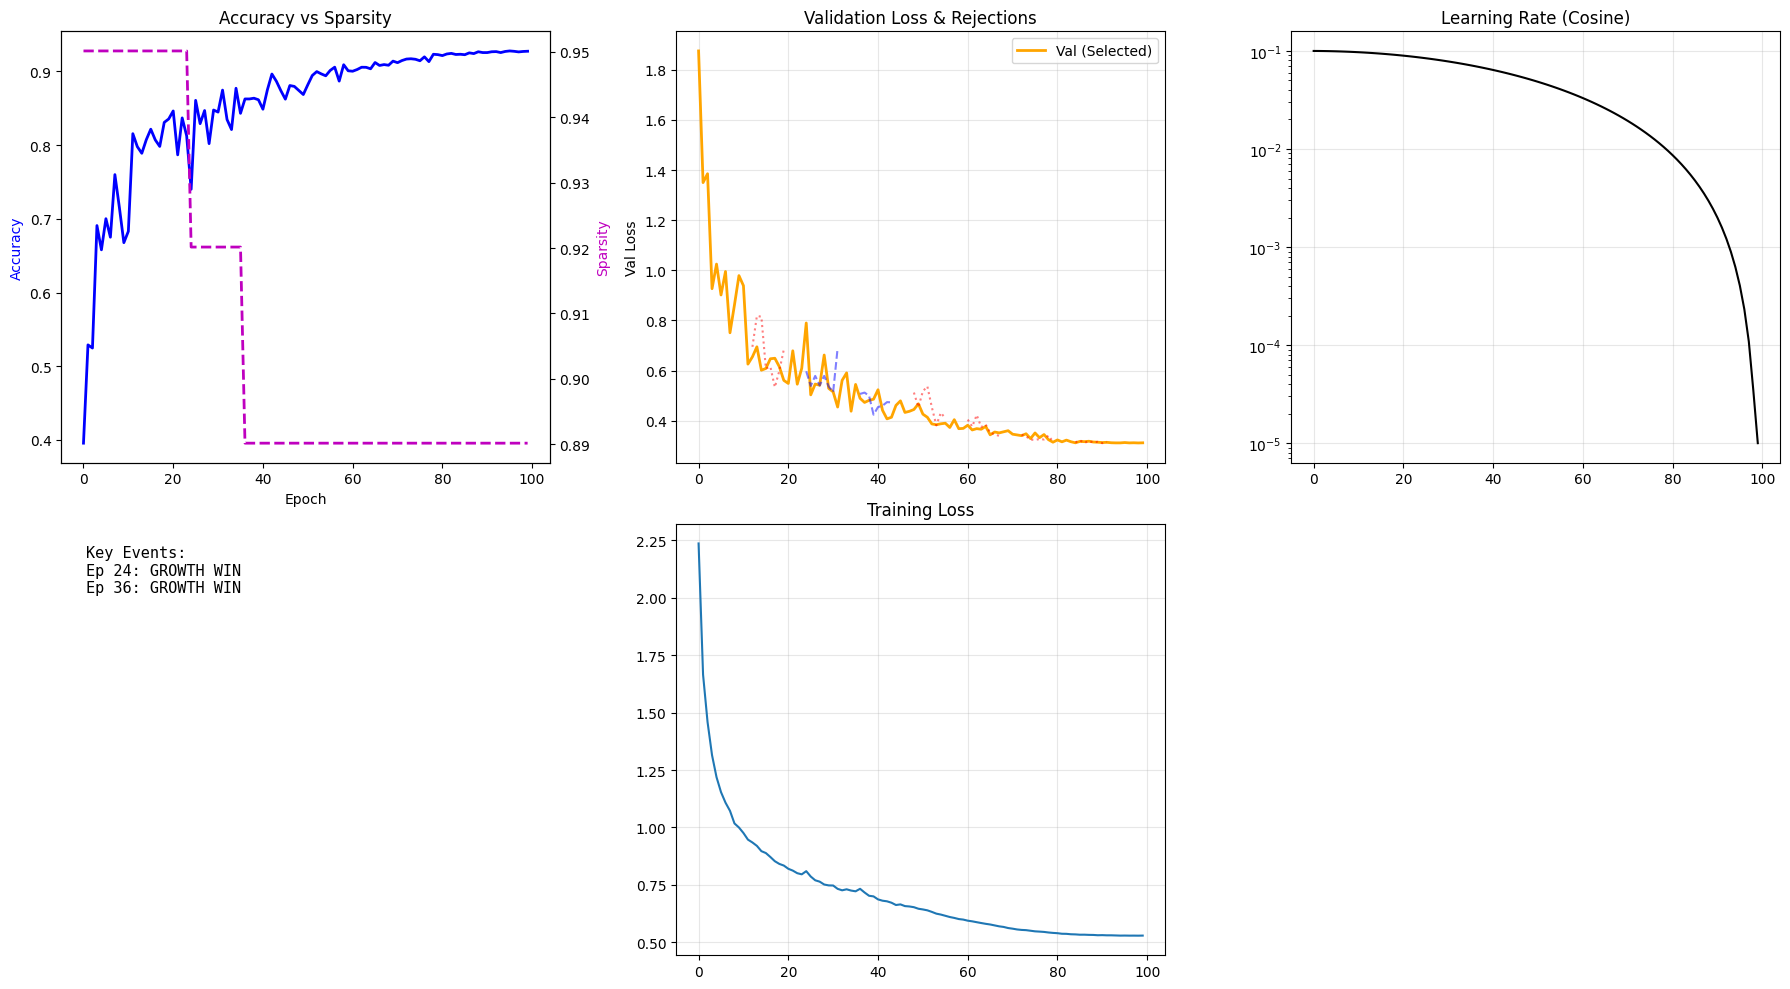

In [ ]:
model, history = run_experiment(
    mode='dynamic',
    use_rigl=True,
    use_lookahead=True,

    # Training Params
    epochs=100,
    batch_size=512,
    lr=0.1,
    use_cifar100=False,

    # RigL Params
    init_sparsity=0.95,

    # Growth & Lookahead Params
    lookahead_freq=12,
    lookahead_epochs=8,
    lookahead_metric='ema',
    net_growth_rate=0.03,
    lr_bump_amount=0.00,

    exclude_classes=None,
    plot=True
)